# SPY Same-Day Closing Price & Closing-Range Prediction
### Experiment 2 — CSIS 3360 | Stock Market Analysis

**Research question:** At the market open, can today's opening price and information from previous trading days estimate (1) today's closing price and (2) a useful range for today's closing price?

**Two outputs:**
1. **Point estimate** of the same-day closing price, using Multiple Linear Regression on the *open-to-close return*.
2. **Estimated 80% closing-price interval**, using lower/upper Quantile Regression, with interval calibration on the 2023 validation set.

**Crucial rule:** We pretend it is just after the opening trade. `Open[t]` is known; **High[t], Low[t], Close[t], and full-day Volume[t] are NOT known**. No feature is allowed to use those current-day values.

**Scientific test:** Compare the model with the simple benchmark `Predicted Close = Today's Open`. A high R² on raw prices alone is **not evidence** of useful forecasting.

**Data split:** Train on 2010–2022, calibrate/validate on 2023, test on 2024–2025.

**Dataset:** Use the *same* `spy_us_d.csv` as your original Linear Regression notebook. This notebook does **not** alter the original experiment.

## 1. Import libraries
Uses pandas, NumPy, Matplotlib and scikit-learn. No new API keys or online access are required.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, QuantileRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", lambda x: f"{x:,.5f}")
plt.rcParams["figure.figsize"] = (11, 5)
print("Libraries ready.")

Libraries ready.


## 2. Load and inspect your existing SPY CSV
Put `spy_us_d.csv` or `spy_us_d(2).csv` in the **same folder as this notebook**. We keep observations from 2010–2025. The first ~20 trading days in 2010 are used only to initialize rolling features, so the model starts training once those lagged indicators become available. The CSV must contain `Date`, `Open`, `High`, `Low`, `Close`, `Volume`.

In [2]:
# Accept the original CSV name and the newly uploaded copy without changing the data.
DATA_FILE = next((p for p in [Path("spy_us_d.csv"), Path("spy_us_d(2).csv")] if p.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError(
        "SPY CSV not found. Put spy_us_d.csv or spy_us_d(2).csv "
        "beside this notebook and run the cell again."
    )
print("Data source:", DATA_FILE.name)

raw = pd.read_csv(DATA_FILE)
raw.columns = raw.columns.str.strip()
required_columns = ["Date", "Open", "High", "Low", "Close", "Volume"]
missing_columns = [c for c in required_columns if c not in raw.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}. Found: {raw.columns.tolist()}")

raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
for c in required_columns[1:]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

df = raw.sort_values("Date").reset_index(drop=True)
df = df.loc[(df["Date"] >= "2010-01-01") & (df["Date"] < "2026-01-01")].copy()

if df["Date"].isna().any() or df["Date"].duplicated().any():
    raise ValueError("Invalid or duplicate Date values — inspect the input before modeling.")
if df[required_columns].isna().any().any():
    raise ValueError("Missing daily values — inspect the input before modeling.")
if (df[["Open", "High", "Low", "Close"]] <= 0).any().any() or (df["Volume"] < 0).any():
    raise ValueError("Invalid price or volume detected.")
if ((df["High"] < df[["Open", "Close", "Low"]].max(axis=1)) |
    (df["Low"] > df[["Open", "Close", "High"]].min(axis=1))).any():
    raise ValueError("OHLC values are inconsistent — check the CSV.")

print("Raw rows:", len(raw))
print("2010–2025 rows:", len(df))
print("First date:", df["Date"].min().date())
print("Last date:", df["Date"].max().date())
display(df[required_columns].head())

Data source: spy_us_d(2).csv
Raw rows: 4023
2010–2025 rows: 4023
First date: 2010-01-04
Last date: 2025-12-31


,Date,Open,High,Low,Close,Volume
0,2010-01-04,86.70500,87.48190,86.01500,87.43530,154164947
1,2010-01-05,87.39290,87.69750,87.07710,87.66700,144619532
2,2010-01-06,87.58540,87.93580,87.50890,87.71370,150444938
3,2010-01-07,87.57120,88.20190,87.33580,88.10230,169908131
4,2010-01-08,87.85640,88.43340,87.68590,88.39520,163831612


## 3. Set the **new target**: same-day open-to-close return

Rather than predicting the dollar price directly, model the percentage change **from today's Open to today's Close**:

\[
\text{Intraday\_Return}_t = \frac{\text{Close}_t}{\text{Open}_t}-1
\]

After predicting this return, turn it back into a price:

\[
\widehat{\text{Close}}_t = \text{Open}_t (1+\widehat{\text{Intraday\_Return}}_t)
\]

**Why:** The opening price determines much of the closing price's level. Predicting the *change from the open* is a harder and more meaningful test than regressing raw `Close` on `Open`. The target uses today's close because it is the thing we want to learn/predict, **not** because the model is allowed to see it as an input.

Intraday return summary (percent):


,Open-to-Close Return (%)
count,"4,023.00000"
mean,0.02235
std,0.81786
min,-5.67110
25%,-0.33081
50%,0.05950
75%,0.42882
max,11.18272


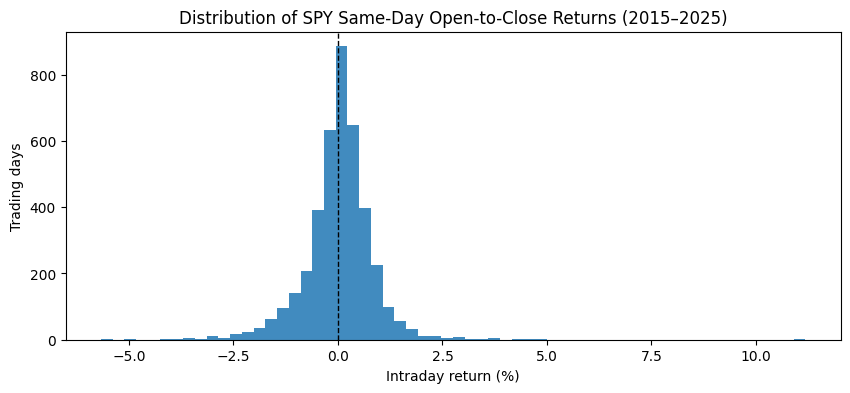

In [3]:
df["Intraday_Return"] = df["Close"] / df["Open"] - 1
print("Intraday return summary (percent):")
display((df["Intraday_Return"] * 100).describe().rename("Open-to-Close Return (%)").to_frame())

plt.figure(figsize=(10, 4))
plt.hist(df["Intraday_Return"] * 100, bins=60, alpha=0.85)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Distribution of SPY Same-Day Open-to-Close Returns (2015–2025)")
plt.xlabel("Intraday return (%)")
plt.ylabel("Trading days")
plt.show()

## 4. Engineer features known **at the opening**

| Feature | Known when? | Meaning |
|---|---|---|
| `Overnight_Gap` | At today's open | Today's Open vs yesterday's Close |
| `Prev_Day_Return` | Yesterday's close | Previous close-to-close return |
| `Prev_5D_Return`, `Prev_20D_Return` | Yesterday's close | Historical momentum ending yesterday |
| `Prev_20D_Volatility` | Yesterday's close | Standard deviation of the past 20 close-to-close returns |
| `Prev_Day_Range` | Yesterday's close | Yesterday's high-to-low range / close |
| `Prev_Volume_Ratio` | Yesterday's close | Yesterday's volume relative to previous 20-day average |
| `Prev_Intraday_Return` | Yesterday's close | Yesterday's open-to-close return |

All features starting with **`Prev_`** use `.shift(1)` so they **cannot see today's full session**. `Open` is used to compute `Overnight_Gap` and to convert predicted returns into closing prices.

In [4]:
# Today's open is known at prediction time; yesterday's completed data is known.
df["Prev_Close"] = df["Close"].shift(1)
df["Overnight_Gap"] = df["Open"] / df["Prev_Close"] - 1

close_to_close_return = df["Close"].pct_change(fill_method=None)
df["Prev_Day_Return"] = close_to_close_return.shift(1)
df["Prev_5D_Return"] = df["Close"].pct_change(5, fill_method=None).shift(1)
df["Prev_20D_Return"] = df["Close"].pct_change(20, fill_method=None).shift(1)
df["Prev_20D_Volatility"] = close_to_close_return.rolling(20).std().shift(1)
df["Prev_Day_Range"] = ((df["High"] - df["Low"]) / df["Close"]).shift(1)
df["Prev_Volume_Ratio"] = (df["Volume"] / df["Volume"].rolling(20).mean()).shift(1)
df["Prev_Intraday_Return"] = df["Intraday_Return"].shift(1)

features = [
    "Overnight_Gap", "Prev_Day_Return", "Prev_5D_Return",
    "Prev_20D_Return", "Prev_20D_Volatility", "Prev_Day_Range",
    "Prev_Volume_Ratio", "Prev_Intraday_Return"
]
target = "Intraday_Return"

df = df.replace([np.inf, -np.inf], np.nan)
model_df = df.dropna(subset=features + [target, "Open", "Close"]).copy().reset_index(drop=True)
print("Modeling observations:", len(model_df))
display(model_df[["Date", "Open", "Prev_Close"] + features + [target]].head())

Modeling observations: 4002


,Date,Open,Prev_Close,Overnight_Gap,Prev_Day_Return,Prev_5D_Return,Prev_20D_Return,Prev_20D_Volatility,Prev_Day_Range,Prev_Volume_Ratio,Prev_Intraday_Return,Intraday_Return
0,2010-02-03,84.76680,85.16780,-0.00471,0.01209,0.00997,-0.02593,0.01062,0.01572,1.08376,0.01046,-0.00037
1,2010-02-04,84.08150,84.73520,-0.00771,-0.00508,0.00000,-0.03344,0.01061,0.00893,0.85230,-0.00037,-0.02324
2,2010-02-05,82.21700,82.12710,0.00109,-0.03078,-0.01969,-0.06369,0.01243,0.02453,1.66148,-0.02324,0.00087
3,2010-02-08,82.35780,82.28890,0.00084,0.00197,-0.00677,-0.06598,0.01236,0.02161,2.12001,0.00087,-0.00800
4,2010-02-09,82.65250,81.69930,0.01167,-0.00717,-0.02913,-0.07575,0.01228,0.01437,0.94303,-0.00800,0.00083


## 5. Chronological train / validation / test periods

- **Train (2010–2022):** Fit models and define baseline quantiles.
- **Validation (2023):** Inspect performance and **calibrate 80% intervals** without touching test data.
- **Test (2024–2025):** Final unbiased-by-test-label comparison. Do not change the model after looking at test results and then report it as a new untouched test.

Historical rolling indicators for January 2023 may include December 2022 values. The first few 2010 observations have no 20-day history and are excluded only because lagged features are undefined. This is **not leakage**: that information was already available at the time.

In [5]:
train = model_df.loc[(model_df["Date"] >= "2010-01-01") & (model_df["Date"] < "2023-01-01")].copy()
validation = model_df.loc[(model_df["Date"] >= "2023-01-01") & (model_df["Date"] < "2024-01-01")].copy()
test = model_df.loc[(model_df["Date"] >= "2024-01-01") & (model_df["Date"] < "2026-01-01")].copy()

if min(len(train), len(validation), len(test)) < 30:
    raise ValueError("Insufficient observations for one or more chronological splits.")
assert train["Date"].max() < validation["Date"].min() < test["Date"].min()
assert train["Date"].dt.year.between(2010, 2022).all()
assert validation["Date"].dt.year.eq(2023).all()
assert test["Date"].dt.year.isin([2024, 2025]).all()

X_train, y_train = train[features], train[target]
X_val, y_val = validation[features], validation[target]
X_test, y_test = test[features], test[target]

print(pd.DataFrame({
    "Period": ["Train", "Validation", "Test"],
    "Start": [part["Date"].min().date() for part in [train, validation, test]],
    "End": [part["Date"].max().date() for part in [train, validation, test]],
    "Rows": [len(part) for part in [train, validation, test]]
}).to_string(index=False))

    Period      Start        End  Rows
     Train 2010-02-03 2022-12-30  3250
Validation 2023-01-03 2023-12-29   250
      Test 2024-01-02 2025-12-31   502


## 6. Establish **two simple point-prediction baselines**

- **Open-price baseline:** `Predicted Close = Today's Open` (predicted intraday return = 0).
- **Historical-mean baseline:** Predict the average open-to-close return observed **only in training**.

Our regression needs to beat these models on *unseen test dates* to establish a useful improvement.

In [6]:
train_mean_return = y_train.mean()
val_pred_open = np.zeros(len(validation))
val_pred_mean = np.full(len(validation), train_mean_return)

def point_metrics(part, predicted_return):
    actual_return = part[target].to_numpy()
    actual_close = part["Close"].to_numpy()
    predicted_return = np.asarray(predicted_return)
    predicted_close = part["Open"].to_numpy() * (1 + predicted_return)
    return {
        "MAE ($)": mean_absolute_error(actual_close, predicted_close),
        "RMSE ($)": np.sqrt(mean_squared_error(actual_close, predicted_close)),
        "MAE (pp)": 100 * mean_absolute_error(actual_return, predicted_return),
        "Return R²": r2_score(actual_return, predicted_return),
        "Price R²*": r2_score(actual_close, predicted_close),
    }

print("Training average intraday return:", f"{train_mean_return * 100:.4f}%")
display(pd.DataFrame({
    "Close = Open": point_metrics(validation, val_pred_open),
    "Historical mean": point_metrics(validation, val_pred_mean)
}).T.round(4))
print("*Price R² is shown only for context — compare MAE/RMSE and return R² instead.")

Training average intraday return: 0.0192%


,MAE ($),RMSE ($),MAE (pp),Return R²,Price R²*
Close = Open,2.27770,2.90850,0.55370,-0.01050,0.98520
Historical mean,2.26540,2.90210,0.55070,-0.00570,0.98530


*Price R² is shown only for context — compare MAE/RMSE and return R² instead.


## 7. Train Multiple Linear Regression for the **point estimate**

The model estimates the *same-day open-to-close return*, not the closing price itself. Then we multiply by today's opening price to obtain a dollar price.

In [7]:
point_model = LinearRegression()
point_model.fit(X_train, y_train)
val_pred_lr = point_model.predict(X_val)

validation_point_results = pd.DataFrame({
    "Close = Open": point_metrics(validation, val_pred_open),
    "Historical mean": point_metrics(validation, val_pred_mean),
    "Linear Regression": point_metrics(validation, val_pred_lr),
}).T.round(4)
print("VALIDATION: 2023 (point forecasts)")
display(validation_point_results)
print("Do NOT pick the best model by Price R² alone.")

VALIDATION: 2023 (point forecasts)


,MAE ($),RMSE ($),MAE (pp),Return R²,Price R²*
Close = Open,2.27770,2.90850,0.55370,-0.01050,0.98520
Historical mean,2.26540,2.90210,0.55070,-0.00570,0.98530
Linear Regression,2.30690,2.94460,0.56060,-0.03500,0.98480


Do NOT pick the best model by Price R² alone.


## 8. Build an estimated **80% closing-price range**

We fit TWO Quantile Regression models to the training data:

- The **10th conditional quantile** is the lower return bound.
- The **90th conditional quantile** is the upper return bound.

Multiplying each return bound by today's `Open` gives a predicted lower/upper *closing price*.

Because quantitative forecasts can be miscalibrated, we also use the **2023 validation set** to adjust each interval's width. This is a simple *split-conformal quantile calibration* approach; it **does not guarantee** 80% coverage in shifting financial markets.

**Baseline range:** A fixed pair of 10th/90th quantiles from training-period open-to-close returns, also adjusted using the same validation calibration process. Neither approach uses 2024–2025 target values to construct its ranges.

In [8]:
LOW_Q, HIGH_Q = 0.10, 0.90
TARGET_COVERAGE = HIGH_Q - LOW_Q  # 80%
REGULARIZATION = 0.00005  # fixed in advance; do not tune on test data

def fit_quantile_model(q):
    m = make_pipeline(
        StandardScaler(),
        QuantileRegressor(quantile=q, alpha=REGULARIZATION, solver="highs")
    )
    m.fit(X_train, y_train)
    return m

q_low_model = fit_quantile_model(LOW_Q)
q_high_model = fit_quantile_model(HIGH_Q)

def ordered_bounds(a, b):
    """Handle occasional crossing of separately fitted quantile regressions."""
    return np.minimum(a, b), np.maximum(a, b)

raw_q_val_low, raw_q_val_high = ordered_bounds(
    q_low_model.predict(X_val), q_high_model.predict(X_val)
)

baseline_low_return, baseline_high_return = np.quantile(y_train, [LOW_Q, HIGH_Q])
raw_base_val_low = np.full(len(validation), baseline_low_return)
raw_base_val_high = np.full(len(validation), baseline_high_return)

print("Training-data fixed baseline return quantiles:",
      f"{baseline_low_return * 100:.2f}%", "to", f"{baseline_high_return * 100:.2f}%")

Training-data fixed baseline return quantiles: -0.91% to 0.84%


## 9. Calibrate the 80% range using **2023 only**

For every validation day, compute how far the actual return is *outside* the proposed interval. Then add a validation-derived correction to widen the interval if needed. A positive correction increases the range; a negative correction is conservatively clipped at 0 (we do not shrink the intervals).

We use an 80% higher-quantile adjustment. This is **not an estimate of market certainty**, and the final coverage must be checked on 2024–2025 data.

In [9]:
def conformal_correction(actual, lower, upper, desired_coverage=0.80):
    actual = np.asarray(actual)
    scores = np.maximum(lower - actual, actual - upper)
    n = len(scores)
    adjusted_q = min(1.0, np.ceil((n + 1) * desired_coverage) / n)
    # Higher order statistic; no negative correction (conservative no-shrinking choice).
    return max(0.0, float(np.quantile(scores, adjusted_q, method="higher")))

q_correction = conformal_correction(
    y_val, raw_q_val_low, raw_q_val_high, TARGET_COVERAGE
)
baseline_correction = conformal_correction(
    y_val, raw_base_val_low, raw_base_val_high, TARGET_COVERAGE
)

print("Quantile Regression validation correction (pp):", round(q_correction * 100, 4))
print("Fixed-quantile baseline correction (pp):", round(baseline_correction * 100, 4))
print("Note: validation is used to CALIBRATE, not as an independent coverage test.")

Quantile Regression validation correction (pp): 0.0955
Fixed-quantile baseline correction (pp): 0.0409
Note: validation is used to CALIBRATE, not as an independent coverage test.


## 10. Predict on the **untouched 2024–2025 test set**

Everything below uses models fit on 2010–2022 data and interval corrections computed on 2023 data. The test targets have not been used for fitting or calibration.

In [10]:
# Point predictions
pred_test_open = np.zeros(len(test))
pred_test_mean = np.full(len(test), train_mean_return)
pred_test_lr = point_model.predict(X_test)

# Conditional quantile intervals; reorder in case quantile lines cross.
q_test_lo_raw, q_test_hi_raw = ordered_bounds(
    q_low_model.predict(X_test), q_high_model.predict(X_test)
)
q_test_lo = q_test_lo_raw - q_correction
q_test_hi = q_test_hi_raw + q_correction

# Unconditional historical-quantile baseline, calibrated by the same method.
base_test_lo = np.full(len(test), baseline_low_return - baseline_correction)
base_test_hi = np.full(len(test), baseline_high_return + baseline_correction)

results = test[["Date", "Open", "Close", "Intraday_Return"]].copy()
results["LR_Predicted_Return"] = pred_test_lr
results["LR_Predicted_Close"] = results["Open"] * (1 + pred_test_lr)
results["Open_Baseline_Close"] = results["Open"]
results["Quantile_Lower_Close"] = results["Open"] * (1 + q_test_lo)
results["Quantile_Upper_Close"] = results["Open"] * (1 + q_test_hi)
results["Baseline_Lower_Close"] = results["Open"] * (1 + base_test_lo)
results["Baseline_Upper_Close"] = results["Open"] * (1 + base_test_hi)

assert (results["Quantile_Lower_Close"] <= results["Quantile_Upper_Close"]).all()
print("First 5 TEST predictions:")
display(results.head().round(4))

First 5 TEST predictions:


,Date,Open,Close,Intraday_Return,LR_Predicted_Return,LR_Predicted_Close,Open_Baseline_Close,Quantile_Lower_Close,Quantile_Upper_Close,Baseline_Lower_Close,Baseline_Upper_Close
3500,2024-01-02,464.78300,465.26600,0.00100,-0.00060,464.49040,464.78300,460.94960,468.37240,460.37750,468.89590
3501,2024-01-03,463.08000,461.46600,-0.00350,-0.00050,462.82640,463.08000,458.91050,466.77010,458.69070,467.17790
3502,2024-01-04,460.98400,459.98000,-0.00220,0.00020,461.09900,460.98400,456.99930,464.96710,456.61450,465.06330
3503,2024-01-05,460.18600,460.61000,0.00090,0.00040,460.37370,460.18600,456.04790,464.34000,455.82410,464.25830
3504,2024-01-08,461.11100,467.18500,0.01320,0.00020,461.19940,461.11100,457.02060,465.07250,456.74030,465.19150


## 11. Evaluate the **same-day closing-price point prediction**

**Primary comparison:** MAE and RMSE **in dollars**, plus MAE in percentage points for the *intraday return*.

A high raw **Price R²** can be misleading because `Open` and `Close` are naturally similar. **Return R²** is much harder to achieve and helps reveal whether we actually predicted the movement from open to close.

In [11]:
test_point_results = pd.DataFrame({
    "Close = Open": point_metrics(test, pred_test_open),
    "Historical mean": point_metrics(test, pred_test_mean),
    "Linear Regression": point_metrics(test, pred_test_lr),
}).T
print("FINAL TEST: 2024–2025 (point prediction)")
display(test_point_results.round(4))

baseline_mae = test_point_results.loc["Close = Open", "MAE ($)"]
model_mae = test_point_results.loc["Linear Regression", "MAE ($)"]
print(f"Linear Regression MAE change vs Close=Open: {100*(model_mae/baseline_mae-1):+.2f}%")
print("Negative MAE change = improvement; positive = worse.")

FINAL TEST: 2024–2025 (point prediction)


,MAE ($),RMSE ($),MAE (pp),Return R²,Price R²*
Close = Open,3.06000,4.83800,0.53660,-0.00060,0.99340
Historical mean,3.05480,4.83800,0.53560,-0.00000,0.99340
Linear Regression,3.03880,4.79590,0.53250,0.02230,0.99350


Linear Regression MAE change vs Close=Open: -0.69%
Negative MAE change = improvement; positive = worse.


## 12. Evaluate the **closing-price interval**

- **Coverage:** Percent of test days whose actual close falls inside the predicted interval. Goal ≈ 80%.
- **Average width ($):** Mean upper minus lower price. Narrower is more useful *at the same coverage*.
- **Interval score:** Lower is better. Penalizes wide intervals **and** misses. We compare against a simple historical-quantile baseline.

**Caution:** Time-series market data can shift across regimes. Chronological validation-calibration does not guarantee any particular future coverage.

In [12]:
def interval_metrics(actual_close, lower, upper, target_coverage=0.80):
    actual_close = np.asarray(actual_close)
    lower = np.asarray(lower)
    upper = np.asarray(upper)
    width = upper - lower
    covered = (actual_close >= lower) & (actual_close <= upper)
    miss_rate = 1 - target_coverage
    # Winkler / interval score: penalizes width and noncoverage.
    score = (width
             + (2 / miss_rate) * np.maximum(lower - actual_close, 0)
             + (2 / miss_rate) * np.maximum(actual_close - upper, 0))
    return {
        "Coverage (%)": 100 * covered.mean(),
        "Avg Width ($)": width.mean(),
        "Avg Width (% of Open)": 100 * np.mean(width / test["Open"].to_numpy()),
        "Interval Score ($, lower=better)": score.mean(),
    }

interval_results = pd.DataFrame({
    "Historical quantiles + calibration": interval_metrics(
        results["Close"], results["Baseline_Lower_Close"], results["Baseline_Upper_Close"]
    ),
    "Quantile Regression + calibration": interval_metrics(
        results["Close"], results["Quantile_Lower_Close"], results["Quantile_Upper_Close"]
    ),
}).T
print("FINAL TEST: 2024–2025 (interval prediction, desired 80% coverage)")
display(interval_results.round(3))
print("Do not prefer a very wide interval merely because it has high coverage.")

FINAL TEST: 2024–2025 (interval prediction, desired 80% coverage)


,Coverage (%),Avg Width ($),Avg Width (% of Open),"Interval Score ($, lower=better)"
Historical quantiles + calibration,86.45400,10.58300,1.83300,15.94400
Quantile Regression + calibration,85.65700,10.43500,1.82300,14.42800


Do not prefer a very wide interval merely because it has high coverage.


## 13. Visualize **actual vs predicted intraday returns**

The dashed diagonal means perfect return prediction. If all points cluster around `predicted = 0`, the model has little ability to predict whether the close will be above or below the open.

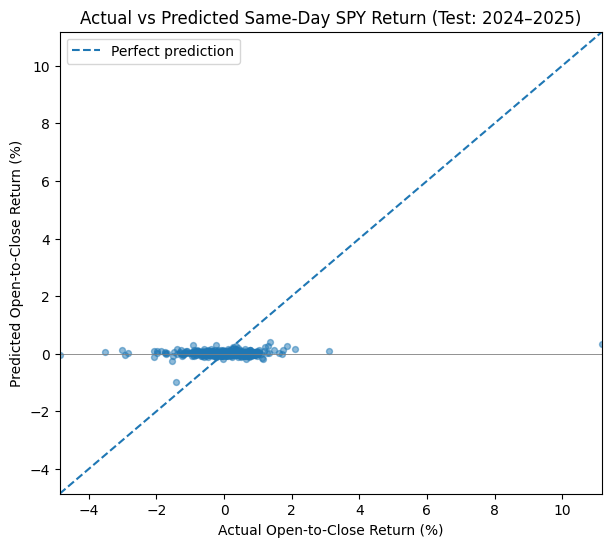

In [13]:
actual_pct = test["Intraday_Return"].to_numpy() * 100
pred_pct = pred_test_lr * 100
plt.figure(figsize=(7, 6))
plt.scatter(actual_pct, pred_pct, alpha=0.5, s=18)
lims = [min(actual_pct.min(), pred_pct.min()), max(actual_pct.max(), pred_pct.max())]
plt.plot(lims, lims, "--", linewidth=1.5, label="Perfect prediction")
plt.xlim(lims); plt.ylim(lims)
plt.axhline(0, color="gray", linewidth=0.6)
plt.xlabel("Actual Open-to-Close Return (%)")
plt.ylabel("Predicted Open-to-Close Return (%)")
plt.title("Actual vs Predicted Same-Day SPY Return (Test: 2024–2025)")
plt.legend()
plt.show()

## 14. Visualize closing prices **and** their errors

A price-level plot will often look impressive even for `Close = Open`. Compare the regression and baseline errors on the same chart to see whether the model adds any real value.

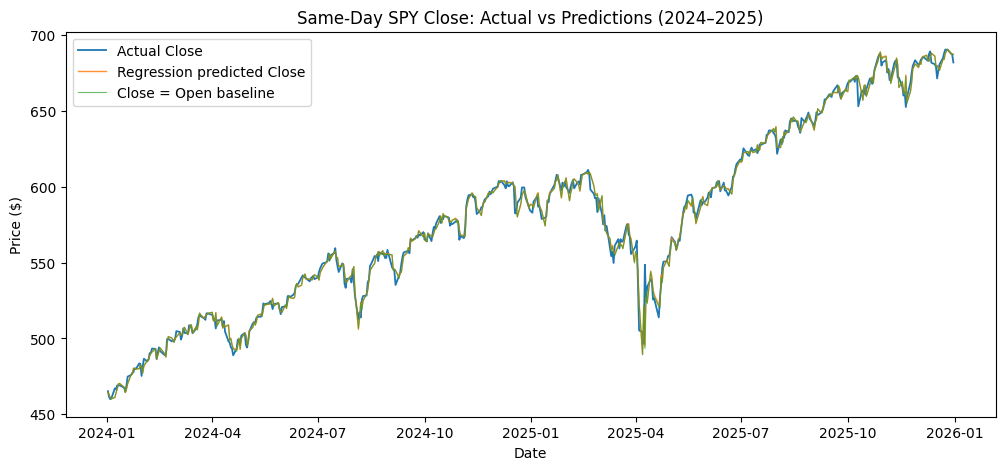

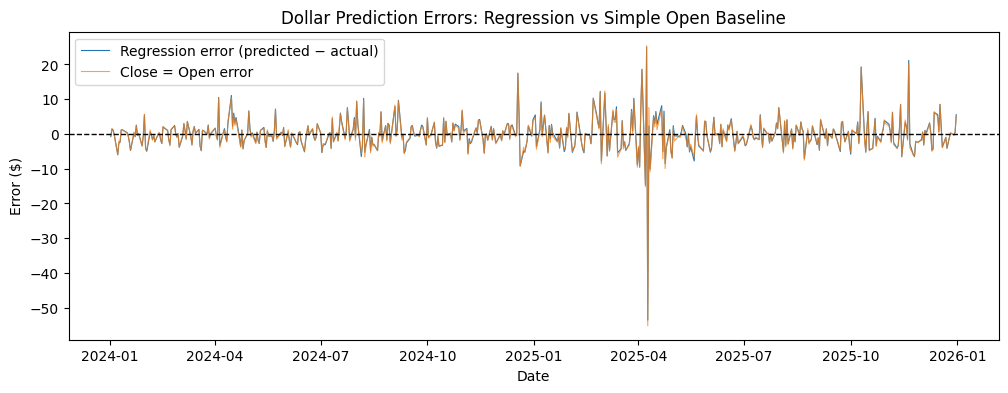

In [14]:
plt.figure(figsize=(12, 5))
plt.plot(results["Date"], results["Close"], label="Actual Close", linewidth=1.3)
plt.plot(results["Date"], results["LR_Predicted_Close"], label="Regression predicted Close", linewidth=1, alpha=0.85)
plt.plot(results["Date"], results["Open_Baseline_Close"], label="Close = Open baseline", linewidth=0.8, alpha=0.7)
plt.title("Same-Day SPY Close: Actual vs Predictions (2024–2025)")
plt.ylabel("Price ($)"); plt.xlabel("Date")
plt.legend(); plt.show()

plt.figure(figsize=(12, 4))
plt.plot(results["Date"], (results["LR_Predicted_Close"]-results["Close"]),
         label="Regression error (predicted − actual)", linewidth=0.8)
plt.plot(results["Date"], (results["Open"]-results["Close"]),
         label="Close = Open error", linewidth=0.8, alpha=0.75)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Dollar Prediction Errors: Regression vs Simple Open Baseline")
plt.ylabel("Error ($)"); plt.xlabel("Date"); plt.legend(); plt.show()

## 15. Visualize the **80% estimated closing-price interval**

For readability, we show the **last 65 test trading days**. Shaded area = model's estimated range; the black line = actual closing price. Unlike High–Low daily range, this is a range for **the closing price**, not for the day's intraday maximum and minimum.

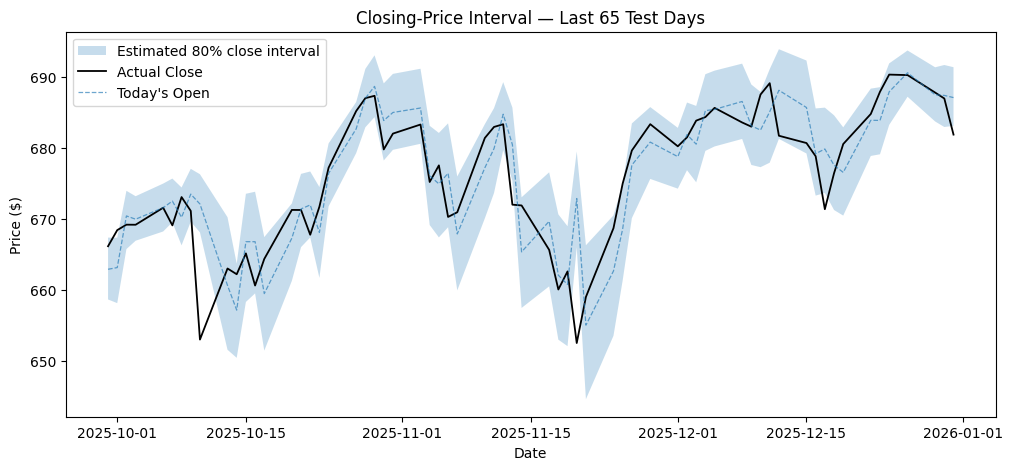

In [15]:
plot_days = results.tail(65).copy()
plt.figure(figsize=(12, 5))
plt.fill_between(plot_days["Date"],
                 plot_days["Quantile_Lower_Close"], plot_days["Quantile_Upper_Close"],
                 alpha=0.25, label="Estimated 80% close interval")
plt.plot(plot_days["Date"], plot_days["Close"], color="black", linewidth=1.3,
         label="Actual Close")
plt.plot(plot_days["Date"], plot_days["Open"], linestyle="--", linewidth=0.9,
         alpha=0.65, label="Today's Open")
plt.title("Closing-Price Interval — Last 65 Test Days")
plt.ylabel("Price ($)"); plt.xlabel("Date")
plt.legend(); plt.show()

## 16. Analyze outliers **without deleting them**

Classify extreme test-period open-to-close returns using **1.5 × IQR thresholds computed on the training period only**. These categories use actual test returns **only after predictions have been made**, for performance analysis, never as input features.

This checks whether model errors are higher on extreme market days. The real market moves are retained in the evaluation.

Training-derived outlier fences: -1.45% to 1.54%
Extreme TEST days: 24 / 502 (4.78%)


,Days,Regression MAE ($)
Group,,
Ordinary test days,478,2.48900
Extreme test days,24,13.98000


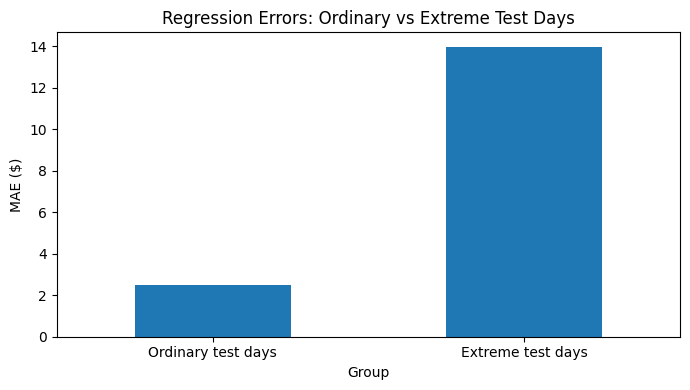

In [16]:
train_q1, train_q3 = np.quantile(y_train, [0.25, 0.75])
train_iqr = train_q3 - train_q1
lower_fence = train_q1 - 1.5 * train_iqr
upper_fence = train_q3 + 1.5 * train_iqr

extreme_flag = (y_test.to_numpy() < lower_fence) | (y_test.to_numpy() > upper_fence)
abs_error_dollars = np.abs(results["LR_Predicted_Close"].to_numpy() - results["Close"].to_numpy())

print(f"Training-derived outlier fences: {lower_fence*100:.2f}% to {upper_fence*100:.2f}%")
print(f"Extreme TEST days: {int(extreme_flag.sum())} / {len(test)} ({100*extreme_flag.mean():.2f}%)")

group_rows=[]
for group_name, mask in [("Ordinary test days", ~extreme_flag), ("Extreme test days", extreme_flag)]:
    if mask.any():
        group_rows.append({"Group": group_name, "Days": int(mask.sum()),
                           "Regression MAE ($)": float(abs_error_dollars[mask].mean())})

outlier_error_table = pd.DataFrame(group_rows).set_index("Group")
display(outlier_error_table.round(3))
if len(outlier_error_table) == 2:
    ax = outlier_error_table["Regression MAE ($)"].plot.bar(figsize=(7,4), rot=0)
    ax.set_title("Regression Errors: Ordinary vs Extreme Test Days")
    ax.set_ylabel("MAE ($)")
    plt.tight_layout(); plt.show()

## 17. Interpret the results **without claiming success prematurely**

Answer these questions **after executing the notebook with real data**:

1. Does Linear Regression beat the `Close = Open` baseline on **MAE ($)** and **RMSE ($)**? If not, it adds little measurable value.
2. Is **Return R²** positive? If not, it is failing to explain the intraday return variation relative to predicting the evaluation-period mean.
3. Does the **80% interval** actually cover close to 80% of test closing prices? Is it narrower or better-scoring than the fixed historical-quantile range?
4. Do large-return days have larger errors? **Do not remove genuine outliers merely to improve the score.**
5. Does the interval add practical information, or is it so wide that it is unhelpful?

**Limits:** The dataset has daily OHLCV bars, not minute-by-minute prices. We therefore predict with information available *at the open*; we cannot honestly use today's intraday high, low, or full volume. Stock market conditions may shift, which can undermine previously calibrated coverage. This is a classroom forecasting study, not a validated trading strategy.

In [17]:
print("=== PRESENTATION SUMMARY (computed from your actual test results) ===")
print(f"Test period: {test['Date'].min().date()} to {test['Date'].max().date()} ({len(test)} trading days)")
print(f"Close=Open MAE: ${test_point_results.loc['Close = Open', 'MAE ($)']:.3f}")
print(f"Linear Regression MAE: ${test_point_results.loc['Linear Regression', 'MAE ($)']:.3f}")
print(f"Linear Regression return R²: {test_point_results.loc['Linear Regression', 'Return R²']:.4f}")
print(f"Quantile interval test coverage: {interval_results.loc['Quantile Regression + calibration', 'Coverage (%)']:.1f}%")
print(f"Quantile interval average width: ${interval_results.loc['Quantile Regression + calibration', 'Avg Width ($)']:.2f}")

if model_mae < baseline_mae:
    print("Point forecast conclusion: Regression BEAT the Close=Open baseline on MAE.")
else:
    print("Point forecast conclusion: Regression did NOT beat the Close=Open baseline on MAE.")

q_cov = interval_results.loc['Quantile Regression + calibration', 'Coverage (%)']
q_score = interval_results.loc['Quantile Regression + calibration', 'Interval Score ($, lower=better)']
b_score = interval_results.loc['Historical quantiles + calibration', 'Interval Score ($, lower=better)']
print(f"Interval conclusion: Test coverage was {q_cov:.1f}% (80% target).")
print("Interval score vs historical-quantile baseline:",
      "BETTER" if q_score < b_score else "NOT BETTER")

=== PRESENTATION SUMMARY (computed from your actual test results) ===
Test period: 2024-01-02 to 2025-12-31 (502 trading days)
Close=Open MAE: $3.060
Linear Regression MAE: $3.039
Linear Regression return R²: 0.0223
Quantile interval test coverage: 85.7%
Quantile interval average width: $10.43
Point forecast conclusion: Regression BEAT the Close=Open baseline on MAE.
Interval conclusion: Test coverage was 85.7% (80% target).
Interval score vs historical-quantile baseline: BETTER


## 18. What to say to your professor

> **Objective:** My second experiment investigates whether information available at the opening of an SPY trading session can estimate that session's closing price and a likely closing-price interval.
>
> **Target:** I predict the *open-to-close percentage return* and convert it into a closing price using the day's Open. This prevents a high price-level R² from being mistaken for strong forecasting skill.
>
> **Features:** I use today's opening gap plus yesterday's completed momentum, volatility, trading range, and volume indicators. All lagged features are shifted one trading day to avoid data leakage.
>
> **Time split:** Training data spans 2010–2022 (after the 20-day indicator warm-up), validation/calibration uses 2023, and testing uses 2024–2025.
>
> **Methods:** I use Multiple Linear Regression for the point forecast and calibrated Quantile Regression for an 80% closing-price interval. I compare them with the simple `Close = Open` and historical-quantile baselines.
>
> **Evaluation:** I report dollar MAE/RMSE, return R², interval coverage, interval width, and interval score on 2024–2025 test data.
>
 **Final finding:** [Fill in *after running* Sections 11–12. Do not claim improved prediction without comparing with the baselines.]

---

### Notebook map (where to find things)
- **Section 3** — New target: `Intraday_Return`
- **Section 4** — No-leakage predictors
- **Sections 6–7** — Point baseline vs Linear Regression
- **Sections 8–9** — 80% predicted interval and validation calibration
- **Sections 11–12** — FINAL RESULTS: point errors and interval quality
- **Sections 13–16** — Scatterplot, timelines, predicted interval, and outliers
- **Section 17** — Interpretation and limitations

*Model inputs assume today's opening price is observable. Historical daily candles do not support live 10:00 AM or intraday-minute predictions.*